# MLP Valuation Head Sensitivity Analysis

This notebook evaluates how MPC performance degrades as the V₀ estimator (MLPValuationHead)
is trained on fewer rollout episodes.

For each value of `n_episodes` ∈ {10, 25, 50, 100, 200, 500}, a separate MLP was trained
on the `survival-second-price-exponential` (clip, η=50) scenario and used to run
MPC(H=10), MPC(H=25), MPCTimeBinned(H=10,K=2), MPCTimeBinned(H=25,K=2).

Each experiment is a separate SLURM job produced by `run_mlp_sensitivity.sh`.
CSVs land in `benchmark/benchmark_results/mlp_sensitivity/` with names
`survival-second-price-exponential_eta50_ep{N}.csv`.
MLP metadata (including validation loss) is in the corresponding `.json` files
under `benchmark/models/mlp_valuation_head/`.


In [1]:
import sys, pathlib, os
# Notebooks live in benchmark/notebooks/; go two levels up to reach repo root
_nb_file = globals().get("__vsc_ipynb_file__") or __file__
repo_root = pathlib.Path(_nb_file).resolve().parent.parent.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
os.chdir(repo_root)  # makes all relative paths resolve from repo root

In [2]:
%matplotlib inline
import glob, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from benchmark.evaluate import score_matrix
from benchmark import plots

## 1. Load results

One CSV per `n_episodes` value. Each is matched with its MLP `.json` metadata
to extract the final validation loss.

In [3]:
SCENARIO_ID = "survival-second-price-exponential"
ETA = 50
MLP_DIR = repo_root / "benchmark/models/mlp_valuation_head"
SENS_DIR = repo_root / "benchmark/benchmark_results/rebuttal"

# Discover result CSVs
_csv_pattern = str(SENS_DIR / f"{SCENARIO_ID}_eta{ETA}_ep*.csv")
_csv_files = sorted(glob.glob(_csv_pattern))
if not _csv_files:
    raise FileNotFoundError(
        f"No sensitivity CSVs found matching {_csv_pattern!r}.\n"
        "Run: for N in 10 25 50 100 200 500; do "
        "N_EPISODES=$N sbatch --job-name=mlp_sens_ep${N} benchmark/run_mlp_sensitivity.sh; done"
    )

records = []  # one dict per (n_episodes, mpc_variant)
dfs = []      # raw per-step DataFrames for detailed plots

for _csv in _csv_files:
    # Extract n_episodes from filename
    m = re.search(r'_ep(\d+)\.csv$', _csv)
    if not m:
        continue
    n_ep = int(m.group(1))

    # Load result CSV
    _df = pd.read_csv(_csv)
    _df['n_episodes'] = n_ep
    dfs.append(_df)

    # Load matching MLP JSON metadata
    _json_pattern = str(MLP_DIR / f"{SCENARIO_ID}_h64-64_acttanh_ep{n_ep}_e500_lr0.001_s42.json")
    _json_files = glob.glob(_json_pattern)
    val_loss = float('nan')
    train_loss = float('nan')
    if _json_files:
        with open(_json_files[0]) as _f:
            _meta = json.load(_f)
        val_loss = _meta.get('final_val_loss', float('nan'))
        train_loss = _meta.get('final_train_loss', float('nan'))
    else:
        print(f'  [WARNING] No JSON metadata found for n_episodes={n_ep}')

    # Episode reward per policy per seed
    _ep_reward = (
        _df.sort_values(['policy', 'seed', 'step'])
        .groupby(['policy', 'seed'])['cum_reward'].last()
        .reset_index()
        .rename(columns={'cum_reward': 'episode_reward'})
    )
    for policy, grp in _ep_reward.groupby('policy'):
        records.append({
            'n_episodes': n_ep,
            'val_loss': val_loss,
            'train_loss': train_loss,
            'policy': policy,
            'mean_reward': grp['episode_reward'].mean(),
            'std_reward': grp['episode_reward'].std(),
            'iqm_reward': grp['episode_reward'].quantile([0.25, 0.75]).mean(),
        })

summary = pd.DataFrame(records).sort_values(['policy', 'n_episodes'])
df_all = pd.concat(dfs, ignore_index=True)

print(f"Loaded {len(_csv_files)} CSV(s) for n_episodes = {sorted(summary['n_episodes'].unique())}")
print(f"Policies: {list(summary['policy'].unique())}")
summary.head(12)

Loaded 6 CSV(s) for n_episodes = [np.int64(10), np.int64(25), np.int64(50), np.int64(100), np.int64(200), np.int64(500)]
Policies: ['MPC(H=10)', 'MPC(H=25)', 'MPCTimeBinned(H=10,K=2)', 'MPCTimeBinned(H=25,K=2)']


,n_episodes,val_loss,train_loss,policy,mean_reward,std_reward,iqm_reward
0,10,0.039803,0.013146,MPC(H=10),1.060274,1.988904,0.912516
12,25,0.039405,0.008408,MPC(H=10),1.714571,2.106894,1.390869
16,50,0.042932,0.025714,MPC(H=10),1.780635,2.216571,1.485142
4,100,0.017477,0.009350,MPC(H=10),2.113191,2.348233,1.780802
8,200,0.006280,0.004148,MPC(H=10),2.155578,2.347113,1.823261
20,500,0.002604,0.001795,MPC(H=10),2.175454,2.345478,1.887754
1,10,0.039803,0.013146,MPC(H=25),1.043531,1.936342,0.859599
13,25,0.039405,0.008408,MPC(H=25),1.841656,2.337397,1.436269
17,50,0.042932,0.025714,MPC(H=25),1.845213,2.308449,1.457592
5,100,0.017477,0.009350,MPC(H=25),2.210093,2.520292,1.794391


## 2. MLP training quality

Validation loss per `n_episodes`. Lower is better.

In [4]:
mlp_quality = (
    summary.drop_duplicates('n_episodes')[['n_episodes', 'val_loss', 'train_loss']]
    .sort_values('n_episodes')
    .reset_index(drop=True)
)
mlp_quality

,n_episodes,val_loss,train_loss
0,10,0.039803,0.013146
1,25,0.039405,0.008408
2,50,0.042932,0.025714
3,100,0.017477,0.009350
4,200,0.006280,0.004148
5,500,0.002604,0.001795


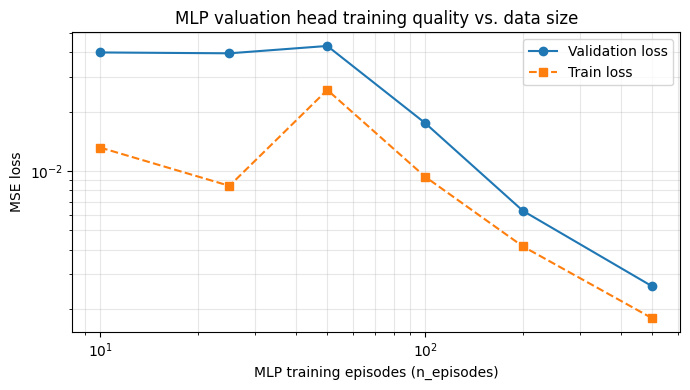

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(mlp_quality['n_episodes'], mlp_quality['val_loss'], marker='o', label='Validation loss')
ax.plot(mlp_quality['n_episodes'], mlp_quality['train_loss'], marker='s', linestyle='--', label='Train loss')
ax.set_xlabel('MLP training episodes (n_episodes)')
ax.set_ylabel('MSE loss')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('MLP valuation head training quality vs. data size')
ax.legend()
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.savefig('mlp_sensitivity_training_loss.pdf')
plt.show()

## 3. MPC performance vs. MLP data size

Mean episode reward (±1 std) for each MPC variant as a function of `n_episodes`.
The rightmost point (n_episodes=500) is the 'well-trained' baseline.

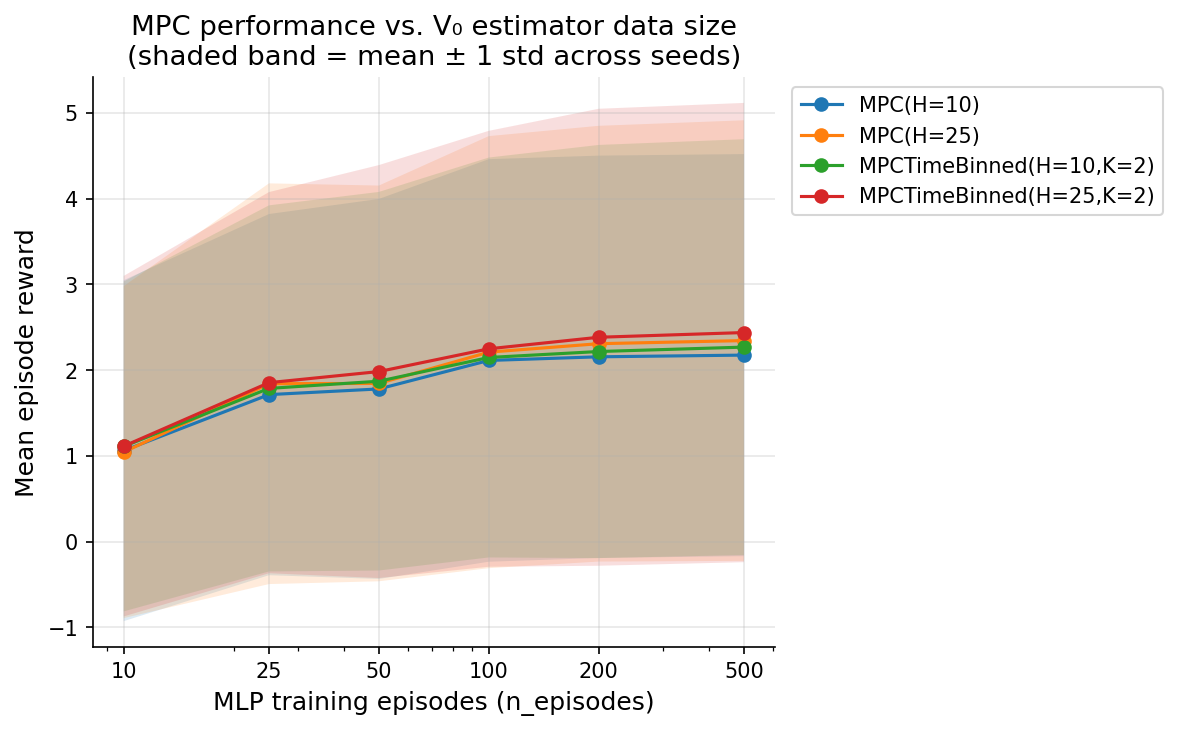

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))

for policy, grp in summary.groupby('policy'):
    grp = grp.sort_values('n_episodes')
    ax.plot(grp['n_episodes'], grp['mean_reward'], marker='o', label=policy)
    ax.fill_between(
        grp['n_episodes'],
        grp['mean_reward'] - grp['std_reward'],
        grp['mean_reward'] + grp['std_reward'],
        alpha=0.15,
        label='_nolegend_',
    )

ax.set_xlabel('MLP training episodes (n_episodes)')
ax.set_ylabel('Mean episode reward')
ax.set_xscale('log')
ax.set_xticks(sorted(summary['n_episodes'].unique()))
ax.get_xaxis().set_major_formatter(ticker.ScalarFormatter())
ax.set_title('MPC performance vs. V₀ estimator data size\n(shaded band = mean ± 1 std across seeds)')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('mlp_sensitivity_vs_nepisodes.pdf')
plt.show()

In [13]:
# Table: mean ± std per policy × n_episodes
_n_eps = sorted(summary['n_episodes'].unique())
_rows = {}
for policy in sorted(summary['policy'].unique()):
    _sub = summary[summary['policy'] == policy].set_index('n_episodes')
    _rows[policy] = {
        n: f"{_sub.loc[n, 'mean_reward']:.3f} ± {_sub.loc[n, 'std_reward']:.3f}"
        for n in _n_eps
    }

_display = pd.DataFrame(_rows).T
_display.columns.name = 'n_episodes'
_display.index.name = 'Policy'
print('Mean episode reward ± 1 std (across 500 seeds)\n')
_display

Mean episode reward ± 1 std (across 500 seeds)



n_episodes,10,25,50,100,200,500
Policy,,,,,,
MPC(H=10),1.060 ± 1.989,1.715 ± 2.107,1.781 ± 2.217,2.113 ± 2.348,2.156 ± 2.347,2.175 ± 2.345
MPC(H=25),1.044 ± 1.936,1.842 ± 2.337,1.845 ± 2.308,2.210 ± 2.520,2.309 ± 2.542,2.345 ± 2.570
"MPCTimeBinned(H=10,K=2)",1.110 ± 1.924,1.787 ± 2.136,1.871 ± 2.209,2.148 ± 2.333,2.217 ± 2.410,2.269 ± 2.426
"MPCTimeBinned(H=25,K=2)",1.113 ± 1.986,1.854 ± 2.223,1.983 ± 2.409,2.249 ± 2.543,2.384 ± 2.666,2.439 ± 2.679


## 4. MPC performance vs. MLP validation loss

This is the more principled view: performance as a function of estimator quality
(validation MSE), independent of how many episodes were used to reach that quality.

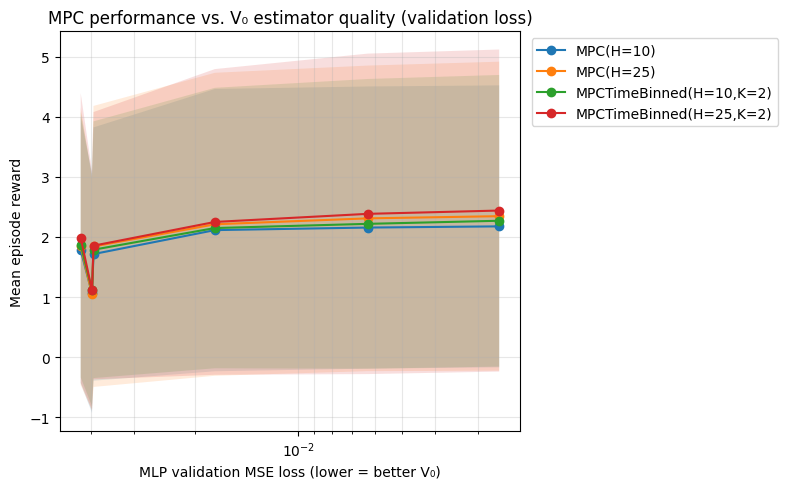

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

for policy, grp in summary.groupby('policy'):
    grp = grp.sort_values('val_loss')
    ax.plot(grp['val_loss'], grp['mean_reward'], marker='o', label=policy)
    ax.fill_between(
        grp['val_loss'],
        grp['mean_reward'] - grp['std_reward'],
        grp['mean_reward'] + grp['std_reward'],
        alpha=0.15,
    )

ax.set_xlabel('MLP validation MSE loss (lower = better V₀)')
ax.set_ylabel('Mean episode reward')
ax.invert_xaxis()  # better V0 (lower loss) on the right
ax.set_xscale('log')
ax.set_title('MPC performance vs. V₀ estimator quality (validation loss)')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.savefig('mlp_sensitivity_vs_valloss.pdf')
plt.show()

## 5. Heatmap: performance by (policy, n_episodes)

Useful for quick visual inspection.

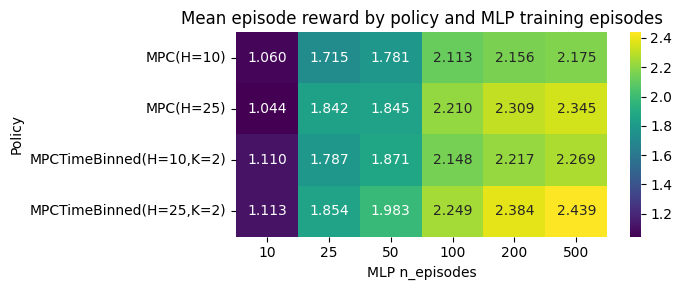

In [9]:
pivot = summary.pivot(index='policy', columns='n_episodes', values='mean_reward')
fig, ax = plt.subplots(figsize=(max(6, len(pivot.columns) * 1.2), max(3, len(pivot) * 0.7)))
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='viridis', ax=ax)
ax.set_title('Mean episode reward by policy and MLP training episodes')
ax.set_xlabel('MLP n_episodes')
ax.set_ylabel('Policy')
plt.tight_layout()
plt.savefig('mlp_sensitivity_heatmap.pdf')
plt.show()

## 6. Reward distributions at key n_episodes

Full distribution (boxplot) for the worst, median, and best MLP quality.

/tmp/ipykernel_16994/731914243.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(_policies, rotation=45, ha='right')
/tmp/ipykernel_16994/731914243.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(_policies, rotation=45, ha='right')
/tmp/ipykernel_16994/731914243.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(_policies, rotation=45, ha='right')


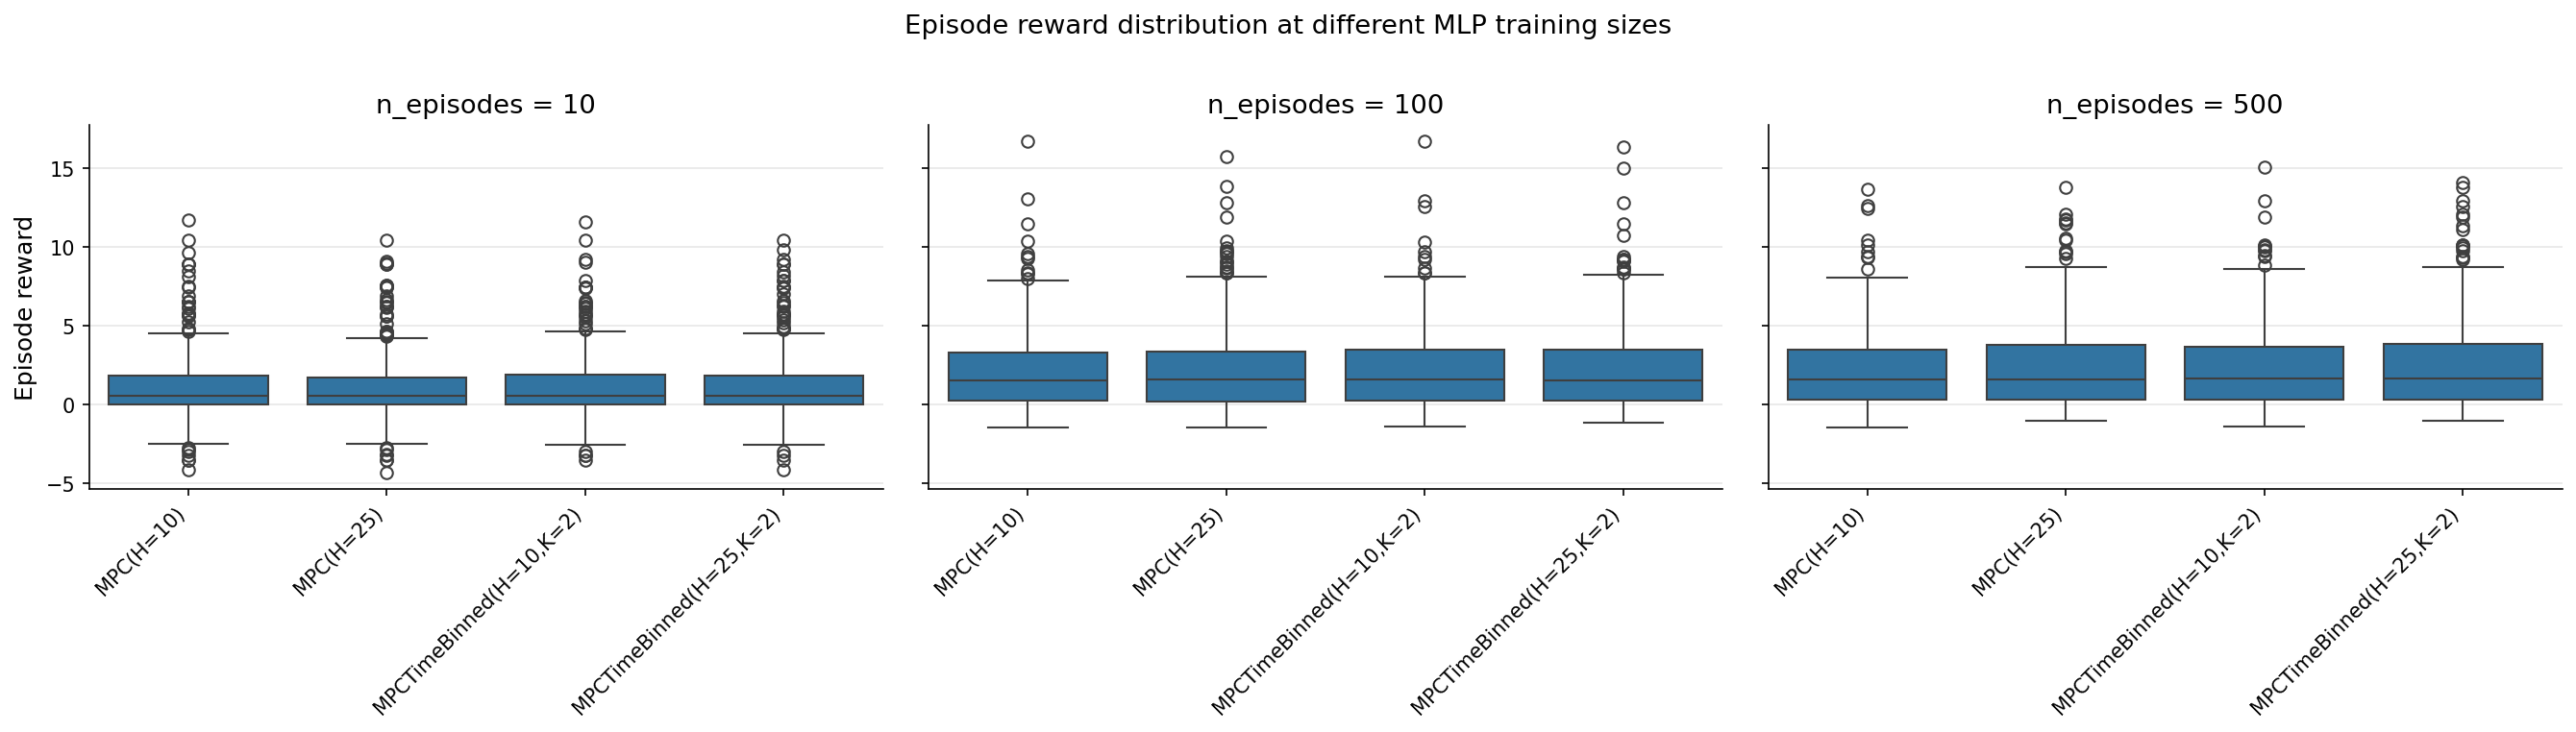

In [10]:
n_ep_values = sorted(df_all['n_episodes'].unique())
# Pick worst (min), middle, best (max)
n_ep_show = [n_ep_values[0], n_ep_values[len(n_ep_values)//2], n_ep_values[-1]]

fig, axes = plt.subplots(1, len(n_ep_show), figsize=(6*len(n_ep_show), 5), sharey=True)

ep_rewards = (
    df_all.sort_values(['policy', 'seed', 'step'])
    .groupby(['n_episodes', 'policy', 'seed'])['cum_reward'].last()
    .reset_index()
    .rename(columns={'cum_reward': 'episode_reward'})
)

for ax, n_ep in zip(axes, n_ep_show):
    _sub = ep_rewards[ep_rewards['n_episodes'] == n_ep]
    _policies = sorted(_sub['policy'].unique())
    sns.boxplot(data=_sub, x='policy', y='episode_reward', order=_policies, ax=ax)
    ax.set_xticklabels(_policies, rotation=45, ha='right')
    ax.set_title(f'n_episodes = {n_ep}')
    ax.set_xlabel('')

axes[0].set_ylabel('Episode reward')
fig.suptitle('Episode reward distribution at different MLP training sizes', y=1.01)
plt.tight_layout()
plt.savefig('mlp_sensitivity_distributions.pdf')
plt.show()

## 7. Performance profiles at best vs. worst MLP

Fraction of seeds exceeding reward threshold τ, comparing the best-trained vs worst-trained MLP.

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/mlp_sensitivity_perf_profile_ep10.pdf


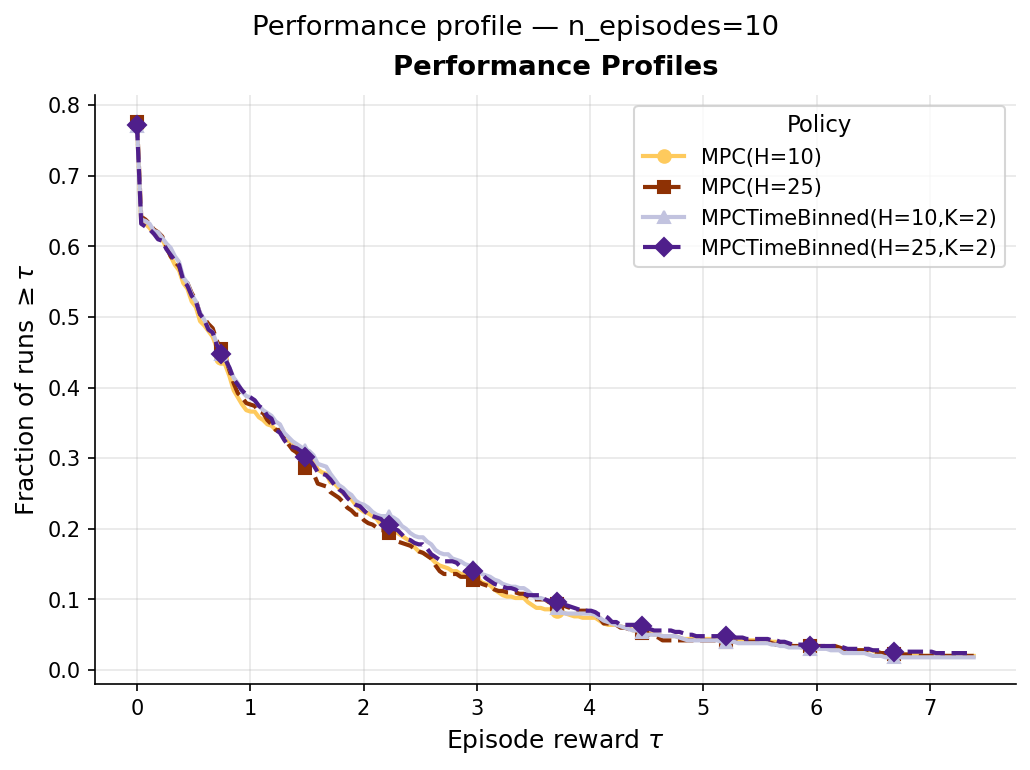

  Saved -> /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/mlp_sensitivity_perf_profile_ep500.pdf


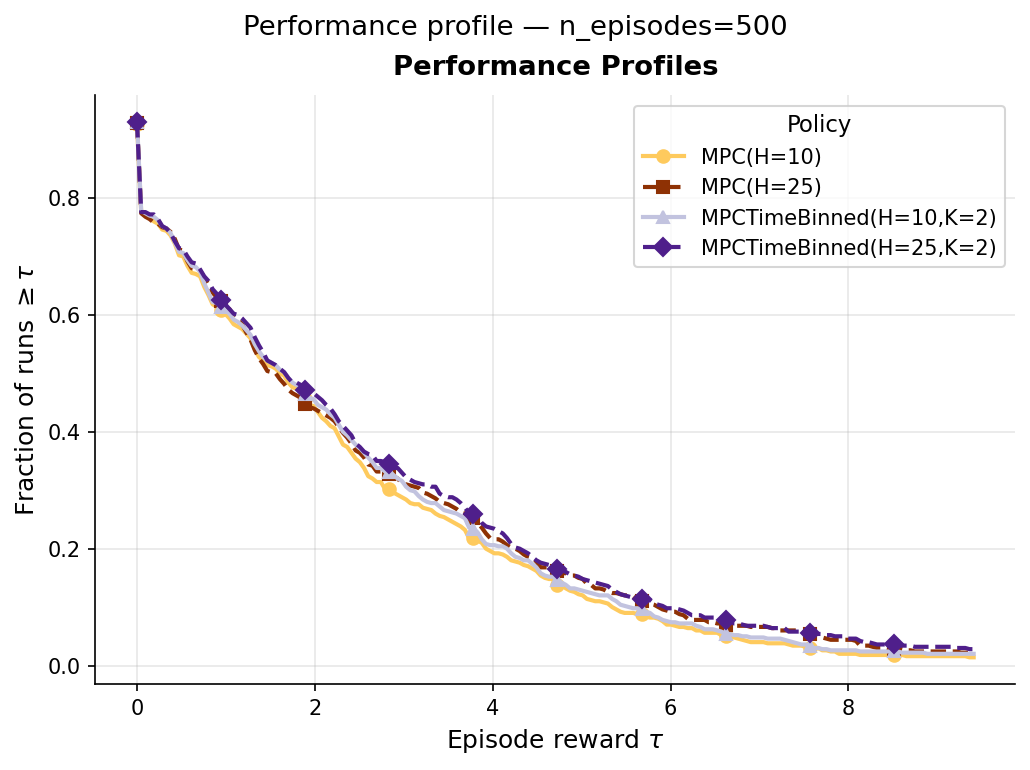

In [11]:
n_ep_best = max(n_ep_values)
n_ep_worst = min(n_ep_values)

for n_ep in [n_ep_worst, n_ep_best]:
    _sub = df_all[df_all['n_episodes'] == n_ep]
    _scores = score_matrix(_sub)
    fig = plots.plot_performance_profiles(
        _scores,
        normalize_by=None,
        filename=f'mlp_sensitivity_perf_profile_ep{n_ep}.pdf',
    )
    fig.suptitle(f'Performance profile — n_episodes={n_ep}', y=1.02)
    plt.show()